# 01 · Datos reales y análisis exploratorio (EDA)

**Fuente principal:** SIATA, archivo abierto `Datos_SIATA_Aire_pm25.json` (PM2.5 horario por estación, jul-2023 a jul-2024). **Complemento:** Open-Meteo (reanálisis ERA5) para meteorología diaria del centro del valle.

Los CSV procesados ya vienen en `data/processed/` (plan B). Para regenerarlos desde las fuentes: `python scripts/download_data.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 140)
from aire import config as C
from aire.data import load_stations, load_daily, load_hourly, load_meteo, daily_matrix, active_stations
from aire.ica import clase_3_array

## 1. Estaciones y cobertura
Una hora es válida si la bandera de calidad de SIATA es ≤ 2.5 y el valor ≥ 0. Un promedio diario requiere ≥ 18 horas válidas (75 %).

In [2]:
st = load_stations()
st[['codigo','nombre_corto','municipio','activa_en_fuente','dias_validos']].sort_values('dias_validos', ascending=False)

,codigo,nombre_corto,municipio,activa_en_fuente,dias_validos
3,28,ITA-CJUS,Itagüí,True,362
13,82,COP-CVID,Copacabana,True,361
20,90,SAB-RAME,Sabaneta,True,359
19,88,ENV-HOSP,Envigado,True,359
9,78,EST-HOSP,La Estrella,True,357
11,80,MED-VILL,Medellín,True,356
5,38,ITA-CONC,Itagüí,True,356
14,83,MED-BEME,Medellín,True,354
12,81,BAR-TORR,Barbosa,True,350
18,87,BEL-FEVE,Bello,True,349


In [3]:
h = load_hourly()
print('Horas totales:', len(h), '| horas válidas:', h.pm25.notna().sum(), f'({h.pm25.notna().mean():.1%})')
M = daily_matrix()
print('Periodo:', M.index.min().date(), 'a', M.index.max().date(), '| estaciones activas:', M.shape[1])
print('Días estación válidos:', int(M.notna().sum().sum()))

Horas totales: 184485 | horas válidas: 138260 (74.9%)
Periodo: 2023-07-31 a 2024-07-31 | estaciones activas: 17
Días estación válidos: 5870


## 2. Distribución de las categorías ICA (Res. 2254/2017)

In [4]:
d = M.stack().dropna().rename('pm25').reset_index().rename(columns={'level_0':'fecha','level_1':'codigo'})
d['clase'] = pd.Categorical(np.array(C.CLASES_CORTAS)[clase_3_array(d.pm25)], C.CLASES_CORTAS)
d['mes'] = d.fecha.dt.to_period('M')
print(d.pm25.describe().round(2))
pd.crosstab(d.mes, d.clase)

count    5870.00
mean       18.73
std         7.63
min         3.11
25%        13.39
50%        16.98
75%        22.36
max        59.00
Name: pm25, dtype: float64


clase,Buena,Aceptable,Dañina
mes,,,
2023-07,5,8,0
2023-08,114,385,0
2023-09,70,428,0
2023-10,100,404,1
2023-11,143,342,0
2023-12,72,429,1
2024-01,35,452,10
2024-02,53,410,20
2024-03,0,428,91


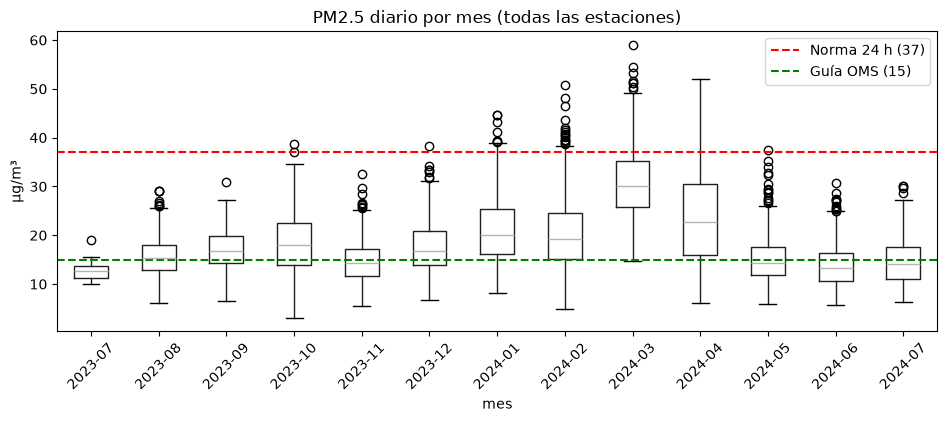

In [5]:
fig, ax = plt.subplots(figsize=(11,4))
d.boxplot(column='pm25', by='mes', ax=ax, grid=False)
ax.axhline(37, color='red', ls='--', label='Norma 24 h (37)'); ax.axhline(15, color='green', ls='--', label='Guía OMS (15)')
ax.set_title('PM2.5 diario por mes (todas las estaciones)'); plt.suptitle(''); ax.set_ylabel('µg/m³'); ax.legend(); plt.xticks(rotation=45); plt.show()

**Observación:** la temporada crítica de 2024 (enero-abril, máximo en marzo) concentra casi todos los días en categoría Naranja; mayo-julio son los meses más limpios. La clase *Dañina* es rara (≈3 % de los días), lo que obliga a usar métricas balanceadas.

## 3. Diferencias entre estaciones

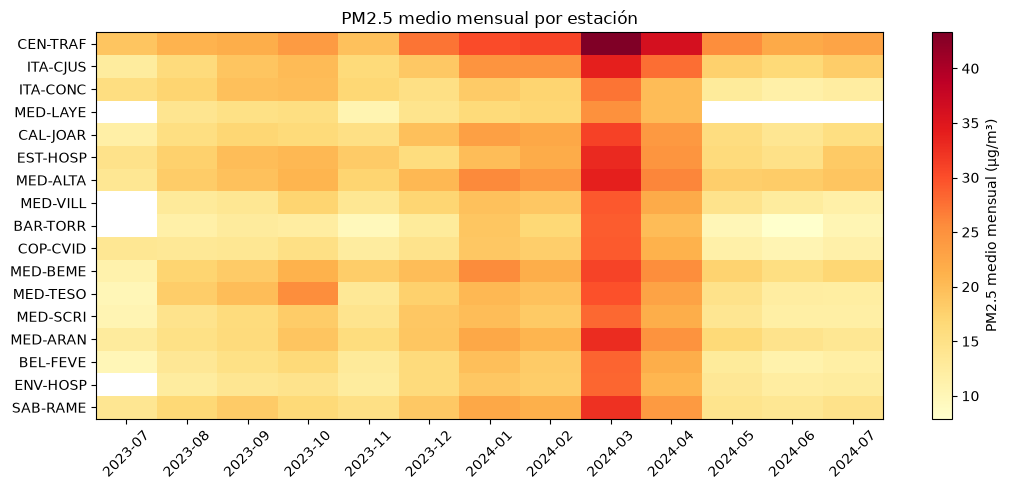

In [6]:
names = active_stations().set_index('codigo')['nombre_corto']
tab = M.rename(columns=names).resample('MS').mean().T.round(1)
fig, ax = plt.subplots(figsize=(11,5)); im = ax.imshow(tab.values, aspect='auto', cmap='YlOrRd')
ax.set_yticks(range(len(tab))); ax.set_yticklabels(tab.index); ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels([c.strftime('%Y-%m') for c in tab.columns], rotation=45)
plt.colorbar(im, label='PM2.5 medio mensual (µg/m³)'); ax.set_title('PM2.5 medio mensual por estación'); plt.tight_layout(); plt.show()

## 4. Persistencia temporal (autocorrelación)
Una autocorrelación alta justifica un modelo con estado latente (HMM) y hace de la persistencia una línea base exigente.

In [7]:
valle = M.mean(axis=1)
print({lag: round(float(valle.autocorr(lag)), 3) for lag in [1, 2, 3, 7, 14]})
same = (d.sort_values(['codigo','fecha']).groupby('codigo').clase.apply(lambda s: (s == s.shift(1)).mean()))
print('Fracción de días con la misma categoría que el día anterior (promedio estaciones):', round(same.mean(), 3))

{1: 0.83, 2: 0.697, 3: 0.63, 7: 0.526, 14: 0.456}
Fracción de días con la misma categoría que el día anterior (promedio estaciones): 0.802


## 5. Meteorología y ciclo semanal / horario

In [8]:
met = load_meteo().set_index('fecha')
j = pd.concat([valle.rename('pm25_valle'), met], axis=1).dropna()
j['pm25_manana'] = j.pm25_valle.shift(-1)
print(j.corr(numeric_only=True)[['pm25_valle','pm25_manana']].round(2))

               pm25_valle  pm25_manana
pm25_valle           1.00         0.83
lluvia_mm           -0.11        -0.19
viento_ms            0.11         0.22
radiacion_mj         0.11         0.22
temp_c               0.38         0.43
humedad_pct         -0.24        -0.33
nubosidad_pct       -0.13        -0.20
pm25_manana          0.83         1.00


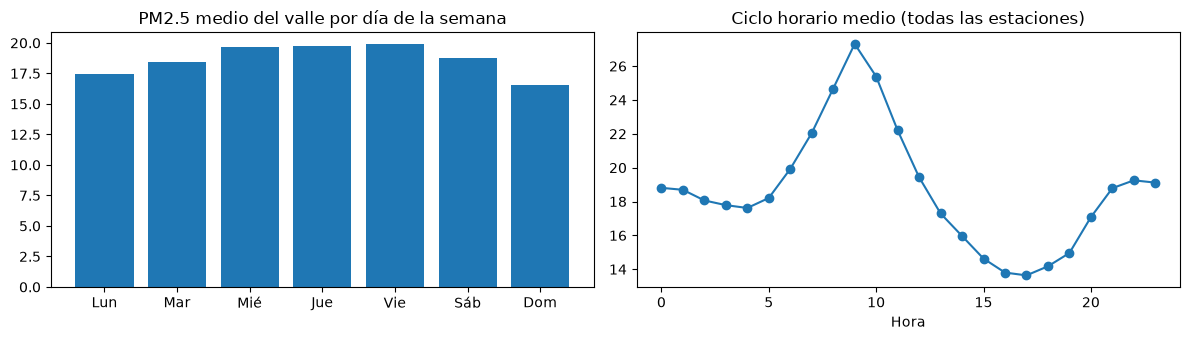

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12,3.5))
dow = valle.groupby(valle.index.day_of_week).mean(); axs[0].bar(['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'], dow.values); axs[0].set_title('PM2.5 medio del valle por día de la semana')
hr = h.groupby(h.fecha.dt.hour).pm25.mean(); axs[1].plot(hr.index, hr.values, marker='o'); axs[1].set_title('Ciclo horario medio (todas las estaciones)'); axs[1].set_xlabel('Hora')
plt.tight_layout(); plt.show()

**Hallazgos del EDA:** (1) fuerte estacionalidad con máximo en marzo; (2) alta persistencia día a día; (3) domingos más limpios (menos tráfico); (4) pico horario en la mañana; (5) la correlación de la meteorología diaria del reanálisis con el PM2.5 es débil y confundida con la estación del año, lo cual se documenta como limitación.